## Middlewares
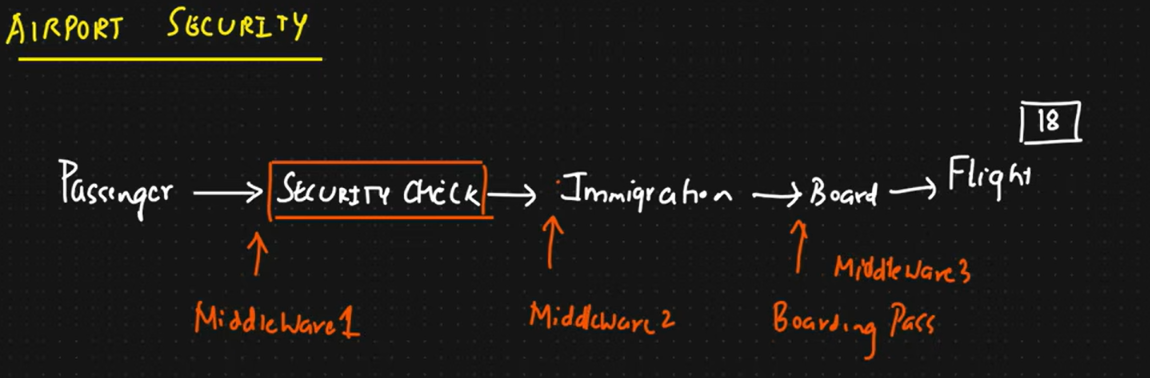

### Middlewares
- middleware is a layer that lets you inspect ,modify or control the agent execution
- It is used for error handling ,logging and monitoring the failures 
- It limits the how many times the model call tools
- pause the execution before any sensitive information
- summarising the long conversations

In [1]:
import os
from dotenv import load_dotenv
load_dotenv()

True

### Summarization Middleware
- The summarization middleware is used for to summarise the long running conversations 
- The two important things in summarization middleware is 'trigger' and 'keep'
- trigger means, when should summarization happens 
- keep means ,How much recent conversation you should remain

In [ ]:
from langchain.agents import create_agent
from langchain.messages import HumanMessage,SystemMessage
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver ## InMemorySaver store the state in RAM


In [13]:
## Now create the agent with middleware 
agent=create_agent(
    model='gpt-6-luna',
    checkpointer=InMemorySaver(), # check pointer 
    middleware=[
      SummarizationMiddleware(
        model='gpt-6-luna',
        trigger=("messages",10), ## trigger point with messages
        keep=("messages",4) ## keep the last 4 messages remain
      )
    ]
)

##  *** without checkpointer the previous conversation between invocations are not persisted
## simple agent process  each question and returns it response 

In [14]:
## without config ,then langgraph cannot determines the converstion state
## whenever u use 'InMemorySaver' u need to use config

config={
  "configurable":{
    "thread_id":"test-1"
  }
}

In [15]:
## test data
questions = [
    "What is 2+2?",
    "What is 10*5?",
    "What is 100/4?",
    "What is 15-7?",
    "What is 3*3?",
    "What is 4*4?",
]

## model invocation
for q in questions:
  response=agent.invoke({'messages':[HumanMessage(content=q)]},config)
  print(f"Messages:{response}")
  print(f"Length of the message:{len(response['messages'])}")

Messages:{'messages': [HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='b06d003d-e8db-4bc5-8ace-347846110881'), AIMessage(content='4', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 13, 'total_tokens': 28, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 5, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': 0, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-6-luna', 'system_fingerprint': None, 'id': 'chatcmpl-EeeKY0tYwLdG3mtHfkVpqe47V59cO', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a18c66-00fb-7b20-bf88-d4191e041bfd-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 13, 'output_tokens': 15, 'total_tokens': 28, 'input_token_details': {'

In [ ]:
## Another two types of triggers

# 1. Tokens-Based-Trigger ==>trigger=("tokens", 4000) → Trigger summarization when the conversation reaches approximately 4,000 tokens
# 2. Fraction-Based-Trigger ==>trigger=("fraction", 0.8) means summarization is triggered when the conversation reaches approximately 80% of the model's context-window capacity.

  # For example, suppose your model has a context window of 100,000 tokens.
  # 100000*0.8=80000

### Human in the loop Middleware
- It means involving human in AI agent 
- It asks for the feedbacks to the human whenever the agent takes a critical decesions

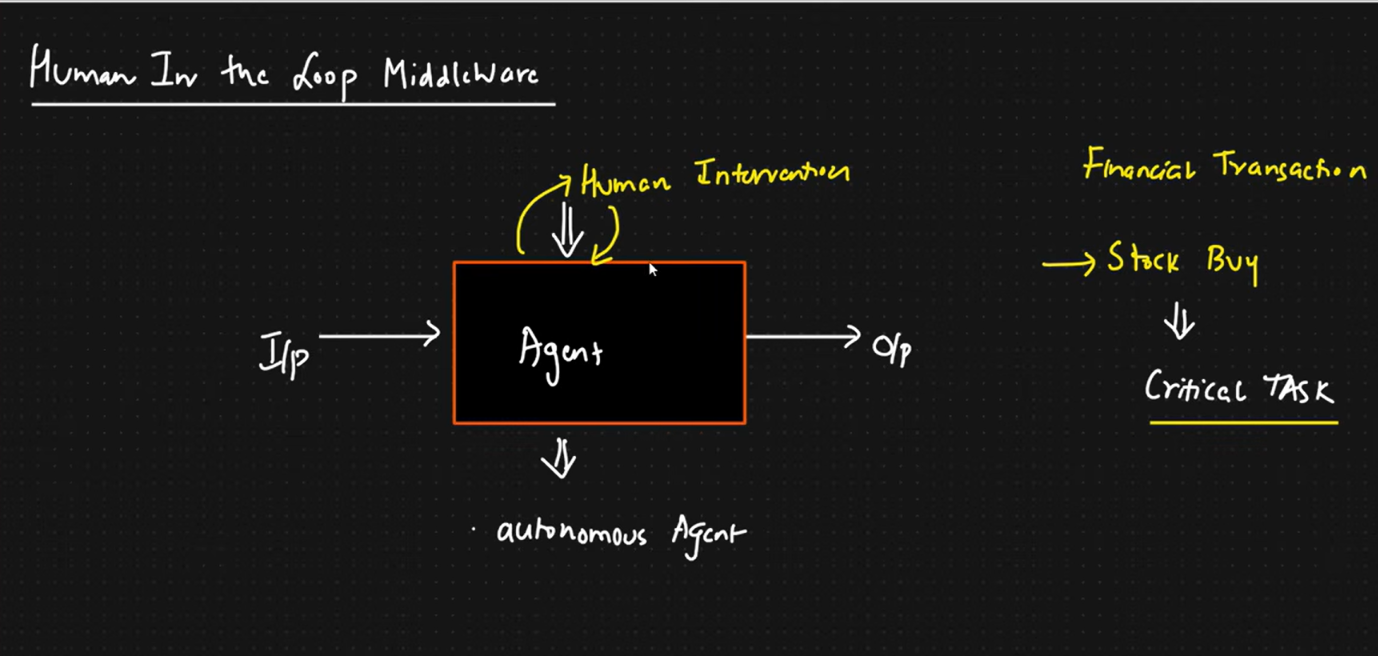

In [30]:
from langchain.tools import tool
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain.messages import HumanMessage


In [25]:
## define tools 
@tool
def read_products_of_client(clientid:int)->str:
  """Get the products from DB by clientid"""
  return f"""The products of the clientid{clientid}
   1.MobilePhone-10000
   2.Tablet-30000
  """

@tool
def addProduct(clientid:int,product_name:str)->str:
  """Adding the new products based on clientid"""
  return f"""
    New product{product_name} added with respect to this clientid {clientid} 
  """


In [41]:
## create the agent
agent=create_agent(
  model='gpt-6-luna',
  checkpointer=InMemorySaver(),
  tools=[addProduct,read_products_of_client],
  middleware=[
    HumanInTheLoopMiddleware(
      ## here the model defining is not needed 
      interrupt_on={
       'addProduct':{
        "allowed_decisions":["approve","edit","reject"]
       },
       'read_products_of_client':False
      }
    )
  ]
)

In [71]:
#config
config = {"configurable": {"thread_id": "test-approve"}}

#invoke the model
response=agent.invoke({
  'messages':[
    HumanMessage(
      content='Please add the redmi note 7 pro to the client 1919'
    )
  ]
},config)
response

{'messages': [HumanMessage(content='Please add the redmi note 7 pro and its price 15000 to the client 1919', additional_kwargs={}, response_metadata={}, id='3eeb50f3-0391-4bcf-b947-e960e3015eb0'),
  AIMessage(content=[{'id': 'rs_0a5ddc7539126555006ae492ce8a2487d2a7a34b6a4e8b8b04', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq5JLPW5Bf5p9FThctwsWaZ8-XPyV3nZHbEeRTDRT4ga6b4nr35BtfAW2ItZwDW3R5OLgTy6dMbEGDAZIMimlmpndk2UEDTDNslpWtkTDGhepa4eFLGp5rs6P5fUUzZua8g7hWsm-3XkZIg_qrlwrSBwsKcrS7Q0ZqAT0LaW80R6L1n9T5SgsXnE-rm95RDWFeKwJwjghS2XX5cQs6RZdIB2W2AsXq7aa55x2QWgdpOaLkZI_CUOw3qtAcHo7c7hxLvv_pJxVTsfNWSNZZGHcQH0Dz5K92MYnAftr22O2cLwrdlNjfTtPY_UVVqciK6eyZeADiCABHdKosog1Ug8lOnkg7Xaya4Kp_cjU-d3IUQE__EicUqHrpWlnHO_MSFdcOqbcZmXJFQ3kypNuOkJL-hcxqu-EN50l4SEwQ1WWQE9hptY43F879sYiUZfrM-UmDcLr5lWUcjl2qm99lru96UWS3oW5sx-AiCgCpy6YNq7yu0niKNL2tApd1YI1-xmx2ig4GZtzFvNtB1h3p7wYG87o8_CPQ6YNe_jfvJsqtRI8Wbu5ujtjP7fyrY9gNKctYBiomqP7v4JifzaJICjdjbFerkfGRzQ5o_dhHC6X_AmaNkCEMnRCj7q_KOVur5

In [72]:
## handling the interrupt

## Approve
from langgraph.types import Command
if '__interrupt__' in response:
  result=agent.invoke(
    Command(
      resume={
        'decisions':[
          {'type':'approve'}
        ]
      }
    ),
    config=config
  )
  print(result['messages'][-1].content[0]['text'])

Added Redmi Note 7 Pro to client 1919.


In [70]:
## reject case handle

if '__interrupt__' in response:
  result=agent.invoke(
    Command(
      resume={
        'decisions':[
          {'type':'reject'}
        ]
      }
    ),
    config=config
  )
  print(result['messages'])
  print(result['messages'][-1].content[0]['text'])


[HumanMessage(content='Please add the redmi note 7 pro and its price 15000 to the client 1919', additional_kwargs={}, response_metadata={}, id='3eeb50f3-0391-4bcf-b947-e960e3015eb0'), AIMessage(content=[{'id': 'rs_0a5ddc7539126555006ae492ce8a2487d2a7a34b6a4e8b8b04', 'summary': [], 'type': 'reasoning', 'content': [], 'encrypted_content': 'gAAAAABq5JLPW5Bf5p9FThctwsWaZ8-XPyV3nZHbEeRTDRT4ga6b4nr35BtfAW2ItZwDW3R5OLgTy6dMbEGDAZIMimlmpndk2UEDTDNslpWtkTDGhepa4eFLGp5rs6P5fUUzZua8g7hWsm-3XkZIg_qrlwrSBwsKcrS7Q0ZqAT0LaW80R6L1n9T5SgsXnE-rm95RDWFeKwJwjghS2XX5cQs6RZdIB2W2AsXq7aa55x2QWgdpOaLkZI_CUOw3qtAcHo7c7hxLvv_pJxVTsfNWSNZZGHcQH0Dz5K92MYnAftr22O2cLwrdlNjfTtPY_UVVqciK6eyZeADiCABHdKosog1Ug8lOnkg7Xaya4Kp_cjU-d3IUQE__EicUqHrpWlnHO_MSFdcOqbcZmXJFQ3kypNuOkJL-hcxqu-EN50l4SEwQ1WWQE9hptY43F879sYiUZfrM-UmDcLr5lWUcjl2qm99lru96UWS3oW5sx-AiCgCpy6YNq7yu0niKNL2tApd1YI1-xmx2ig4GZtzFvNtB1h3p7wYG87o8_CPQ6YNe_jfvJsqtRI8Wbu5ujtjP7fyrY9gNKctYBiomqP7v4JifzaJICjdjbFerkfGRzQ5o_dhHC6X_AmaNkCEMnRCj7q_KOVur5H096_wxiW1a0vGD

In [60]:
# #config
# config = {"configurable": {"thread_id": "edit-approve"}}

# #invoke the model
# response=agent.invoke({
#   'messages':[
#     HumanMessage(
#       content='Please add the redmi note 7 pro and its price 15000 to the client 1919'
#     )
#   ]
# },config)
# response

In [69]:
## handle the edit case

if '__interrupt__' in response:
  print('message was edited...')
  result=agent.invoke(
    Command(
      resume={
        "decisions":[
          {
            "type":"edit",
            "edited_action":{
              "name":"addProduct",
              "args":{
                "clientid":"1818",
                "product_name":"samsung galaxy m31"
              }
            }
          }
        ]
      }
    ),
    config=config
  )

  print(result['messages'][-1].content[0]['text'])

message was edited...
Added Redmi Note 7 Pro to client 1919.
